In [18]:
import pandas as pd
import numpy as np

columns = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

df = pd.read_csv('/content/adult.data', names=columns, skipinitialspace=True, na_values='?')
df.shape

(32561, 15)

In [19]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [20]:
# duplicatlarni o'chiramiz
df = df.drop_duplicates().reset_index(drop=True)

# keraksiz 2 ta ustunni olib tashlaymiz
df = df.drop(columns=['education', 'fnlwgt'])
# income ni 0 va 1 ga o'tkazamiz
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

print("Qolgan ustunlar:", df.columns)
print("Target taqsimoti:\n", df['income'].value_counts())

Qolgan ustunlar: Index(['age', 'workclass', 'education_num', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
       'hours_per_week', 'native_country', 'income'],
      dtype='object')
Target taqsimoti:
 income
0    24698
1     7839
Name: count, dtype: int64


In [21]:
# Sof sarmoya daromadi (foydadan zararni ayiramiz)
df['capital_net'] = df['capital_gain'] - df['capital_loss']

# Oila qurganmi yoki yo'q
df['is_married'] = df['marital_status'].apply(lambda x: 1 if 'Married' in str(x) else 0)

X = df.drop(columns=['income'])
y = df['income']

In [22]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp
)

print("Train soni:", X_train.shape[0])
print("Valid soni:", X_valid.shape[0])
print("Test soni :", X_test.shape[0])
# qanday qismlarga ajralganini ko'rdik

Train soni: 22774
Valid soni: 4882
Test soni : 4881


In [23]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Qaysi ustunlar sonli, qaysilari kategorik ekanini ajratamiz
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Kategorik ustunlar uchun qoida: bo'sh joyni eng ko'p uchragan qiymat (moda) bilan to'ldir
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

# Ikkala qoidani bitta preprocessor'ga birlashtiramiz
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_valid_prep = preprocessor.transform(X_valid)
X_test_prep  = preprocessor.transform(X_test)

print("Tayyor ustunlar soni:", X_train_prep.shape[1])

Tayyor ustunlar soni: 83


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

lr_model = LogisticRegression(max_iter=1000, random_state=42)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
xgb_model = XGBClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='logloss')

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

# Har bir modelni Train da o'qitib, Test da tekshiramiz
for name, model in models.items():
    model.fit(X_train_prep, y_train)

    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4)
    })

print(pd.DataFrame(results).to_string(index=False))

              Model  Accuracy  F1-Score  ROC-AUC
Logistic Regression    0.8564    0.6765   0.9099
      Random Forest    0.8693    0.6823   0.9208
            XGBoost    0.8769    0.7237   0.9309


In [25]:
# 1. Test ma'lumoti uchun har bir modelning ehtimolligini olamiz
p_lr  = lr_model.predict_proba(X_test_prep)[:, 1]
p_rf  = rf_model.predict_proba(X_test_prep)[:, 1]
p_xgb = xgb_model.predict_proba(X_test_prep)[:, 1]

# 2. Kuchli modelga ko'proq vazn berib birlashtiramiz (jami = 1.0)
blend_proba = 0.15 * p_lr + 0.25 * p_rf + 0.60 * p_xgb
blend_pred  = (blend_proba >= 0.5).astype(int)

# 3. Natijani jadvalga qo'shamiz
results.append({
    "Model": "Blending (Weighted)",
    "Accuracy": round(accuracy_score(y_test, blend_pred), 4),
    "F1-Score": round(f1_score(y_test, blend_pred), 4),
    "ROC-AUC": round(roc_auc_score(y_test, blend_proba), 4)
})

print("Blending tayyor!")

Blending tayyor!


In [26]:
from sklearn.ensemble import StackingClassifier

# Bazaviy modellar ro'yxati
base_models = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)),
    ('xgb', XGBClassifier(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='logloss'))
]

# Stacking modelini tuzamiz (Meta-model = LogisticRegression)
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(),
    cv=5
)

stack_model.fit(X_train_prep, y_train)

StackingClassifier(cv=5,
                   estimators=[('lr',
                                LogisticRegression(max_iter=1000,
                                                   random_state=42)),
                               ('rf',
                                RandomForestClassifier(max_depth=12,
                                                       n_estimators=150,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=0.1, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None, max_depth=5,
                                              max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=150, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [27]:
stack_pred  = stack_model.predict(X_test_prep)
stack_proba = stack_model.predict_proba(X_test_prep)[:, 1]

# Natijani jadvalga qo'shamiz
results.append({
    "Model": "Stacking (CV=5)",
    "Accuracy": round(accuracy_score(y_test, stack_pred), 4),
    "F1-Score": round(f1_score(y_test, stack_pred), 4),
    "ROC-AUC": round(roc_auc_score(y_test, stack_proba), 4)
})

# Barcha modellarni ROC-AUC bo'yicha saralab ekranga chiqaramiz
df_results = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print(df_results.to_string(index=False))
# eng katta ROC-AUC scoore-ni XGBoost olgan, bu modellar ichida eng yaxshisi bo'ladi
# agar bizga aniqlik kerak bo'lsa: eng yaxshisi Stacking bo'ladi
# agar bizga tezlik va oson kod yozish kerak bo'lsa: Blending kerak bo'ladi

              Model  Accuracy  F1-Score  ROC-AUC
            XGBoost    0.8769    0.7237   0.9309
    Stacking (CV=5)    0.8758    0.7213   0.9302
Blending (Weighted)    0.8748    0.7127   0.9290
      Random Forest    0.8693    0.6823   0.9208
Logistic Regression    0.8564    0.6765   0.9099


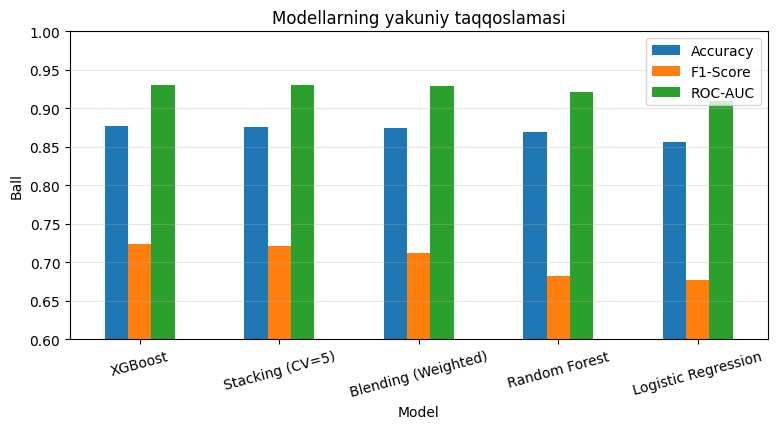

In [28]:
import matplotlib.pyplot as plt

# Modellarning ROC-AUC va F1-Score natijalarini chizamiz
df_results.plot(
    x="Model",
    y=["Accuracy", "F1-Score", "ROC-AUC"],
    kind="bar",
    figsize=(9, 4)
)

plt.title("Modellarning yakuniy taqqoslamasi")
plt.ylabel("Ball")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.show()